# PathSnap — HMM / Viterbi Route Reconstruction (executed)
**Owner:** Pavan

**What we say:** The classifier scores each GPS point independently, so consecutive points can land on roads that are not connected. The **HMM** adds road-network connectivity, and **Viterbi** finds the single most likely sequence of road segments.

*Executed notebook: the decoding below runs live on the 10 student-test trips, using the final model's saved probabilities and the tuned decoder parameters.*

## Step 1 — Setup

In [1]:
# Works on Google Colab (clones repo, data from Drive) or locally inside the repo
import os, sys
try:
    import google.colab  # noqa
    from google.colab import drive; drive.mount('/content/drive')
    !git clone -q https://github.com/GTX-Pradeep/Path_Snap_PT_096.git /content/pathsnap
    !pip install -q lightgbm optuna pyarrow folium
    os.environ['PATHSNAP_DATA'] = '/content/drive/MyDrive/Student folder'   # <- dataset location
    os.chdir('/content/pathsnap/src')
except ImportError:
    os.chdir(os.path.join(os.path.dirname(os.path.abspath('.')), 'src') if os.path.basename(os.path.abspath('.')) == 'notebooks' else 'src')
sys.path.insert(0, '.')
import pandas as pd, json
from IPython.display import Image, display
pd.set_option('display.width', 200)
print('working dir:', os.getcwd())

working dir: /home/user/pathsnap/src


## Step 2 — The model
**What we say:**
* **Hidden states:** for GPS point *i*, its 8 candidate arcs. State *j* at time *i* is always arc `cand[i, j]`, so we never lose which road a state stands for.
* **Emission:** log P(true arc) from the classifier, multiplied by a weight *w*.
* **Transition:** the network distance between two consecutive matched positions should equal the straight GPS step:
  `route_d = rest of arc a + shortest path(end of a → start of b) + part of arc b`, and `log T = −|route_d − gps_d| / β`.
  Shortest paths come from Dijkstra on the directed road graph. On the same arc we use signed progress, so driving backwards is penalised.
* **Disconnected roads:** an unreachable arc gets a large finite penalty, not impossible. The decoder avoids it, but a path always exists.
* **GPS gaps:** if the gap is over 30 s, the transition is unconstrained.
* **Missing candidates:** padded with impossible states.

In [2]:
from hmm import DEFAULT_PARAMS
cfg = json.load(open('../models/final_config.json'))
print('final classifier:', cfg['model_name'])
print('decoder params  :', cfg['hmm_params'])
print('tuned on train trips (out-of-fold probabilities):', cfg['decoder_tuned_on_train_trips'])

final classifier: lgbm_tuned
decoder params  : {'beta': 1.0, 'w_emit': 2.0, 'gap_s': 30.0, 'max_route_m': 1500.0, 'unreachable': -30.0}
tuned on train trips (out-of-fold probabilities): ['00000058', '00000093', '00000018', '00000086', '00000098', '00000090', '00000013', '00000006', '00000048', '00000047', '00000079', '00000008', '00000044', '00000069', '00000085', '00000066', '00000074', '00000035', '00000082', '00000045']


## Step 3 — Decoder tuning (training trips only)
**What we say:** We grid-searched β (transition scale) and *w* (emission weight) on 20 **training** trips. Their probabilities came from 5-fold out-of-fold models, so each trip was scored by a model that never saw it. Tuning on in-sample probabilities would be over-confident.

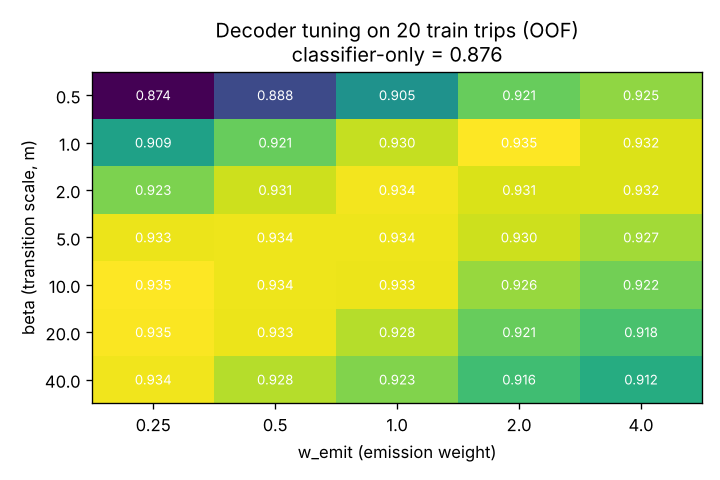

,beta,w_emit,pointwise_accuracy
8,1.0,2.00,0.935072
20,10.0,0.25,0.934866
25,20.0,0.25,0.934789
12,2.0,1.00,0.933939
30,40.0,0.25,0.933759


In [3]:
display(Image('../results/hmm/decoder_tuning.png'))
pd.read_csv('../results/hmm/decoder_tuning.csv').sort_values('pointwise_accuracy', ascending=False).head(5)

## Step 4 — Run the decoder live on the 10 student-test trips
**What we say:** For each trip we compare **classifier only** (best candidate per point) with **classifier + HMM**. Metrics:
* **Pointwise accuracy:** the predicted arc equals the reference arc.
* **Route continuity:** consecutive points sit on the same or directly connected arcs.
* **Breaks:** consecutive points on disconnected arcs.
* **Route F1:** overlap between the predicted and reference arc sets.

In [4]:
import time
from data_loader import load_trip
from features import build_geometry
from hmm import TripDecoder, route_metrics
c = pd.read_parquet('../results/candidates_student_test.parquet')
c['proba'] = pd.read_parquet(f"../results/pred_test_{cfg['model_name']}.parquet").proba.values
rows = []
t0 = time.time()
for t in sorted(c.trip.unique()):
    trip = load_trip('student_test', t); g = build_geometry(trip); ct = c[c.trip == t]
    d = TripDecoder(g, ct, cfg['hmm_params'])
    ref = ct.groupby('obs').ref_arc.first().loc[d.obs].to_numpy()
    for name, pred in [('classifier only', d.classifier_only()), ('classifier + HMM', d.decode())]:
        rows.append(dict(trip=t, method=name, **route_metrics(g, pred, ref, trip['route'])))
print('decoded 10 trips in %.1f s' % (time.time() - t0))
res = pd.DataFrame(rows)
res.pivot(index='trip', columns='method', values='pointwise_accuracy').round(4)

decoded 10 trips in 1.1 s


method,classifier + HMM,classifier only
trip,,
00000000,0.9656,0.9437
00000007,0.8951,0.9025
00000009,0.8980,0.8656
00000040,0.9472,0.9199
00000052,0.9809,0.9580
00000056,0.9611,0.8931
00000065,0.9128,0.8503
00000076,0.9482,0.8822
00000077,0.8471,0.7159


In [5]:
w = res.n_obs
summary = res.groupby('method').apply(lambda d: pd.Series({
    'pointwise_accuracy': (d.pointwise_accuracy * d.n_obs).sum() / d.n_obs.sum(),
    'route_continuity': (d.route_continuity * d.n_obs).sum() / d.n_obs.sum(),
    'breaks': d.n_breaks.sum(), 'route_f1': d.route_f1.mean()}))
summary.round(4)

,pointwise_accuracy,route_continuity,breaks,route_f1
method,,,,
classifier + HMM,0.9243,0.9814,357.0,0.9200
classifier only,0.8637,0.9354,1237.0,0.8575


## Step 5 — Classifier only vs HMM for every model, and example routes
**What we say:** The HMM improves every classifier, most of all the weakest ones. The route figures show the classifier-only arcs jumping between parallel roads, while the HMM route follows one connected path.

,model,method,pointwise_accuracy,route_continuity,breaks,route_precision,route_recall,route_f1,decode_time_s_10_trips
0,knn,classifier only,0.8485,0.9194,1544,0.8002,0.8793,0.8342,NaN
1,knn,classifier + HMM,0.9076,0.9804,376,0.9367,0.9005,0.9165,0.8166
2,lgbm,classifier only,0.8604,0.9346,1252,0.8332,0.8833,0.8538,NaN
3,lgbm,classifier + HMM,0.9241,0.9811,361,0.9497,0.9087,0.9272,0.8694
4,lgbm_tuned,classifier only,0.8637,0.9354,1237,0.8372,0.8861,0.8575,NaN
5,lgbm_tuned,classifier + HMM,0.9243,0.9814,357,0.9417,0.9024,0.9200,0.8945
6,logreg,classifier only,0.8479,0.9215,1503,0.8061,0.8805,0.8376,NaN
7,logreg,classifier + HMM,0.9029,0.9811,361,0.9443,0.9128,0.9267,0.9328
8,mlp,classifier only,0.8565,0.9315,1311,0.8249,0.8815,0.8487,NaN
9,mlp,classifier + HMM,0.9237,0.9810,364,0.9456,0.9064,0.9241,0.8616


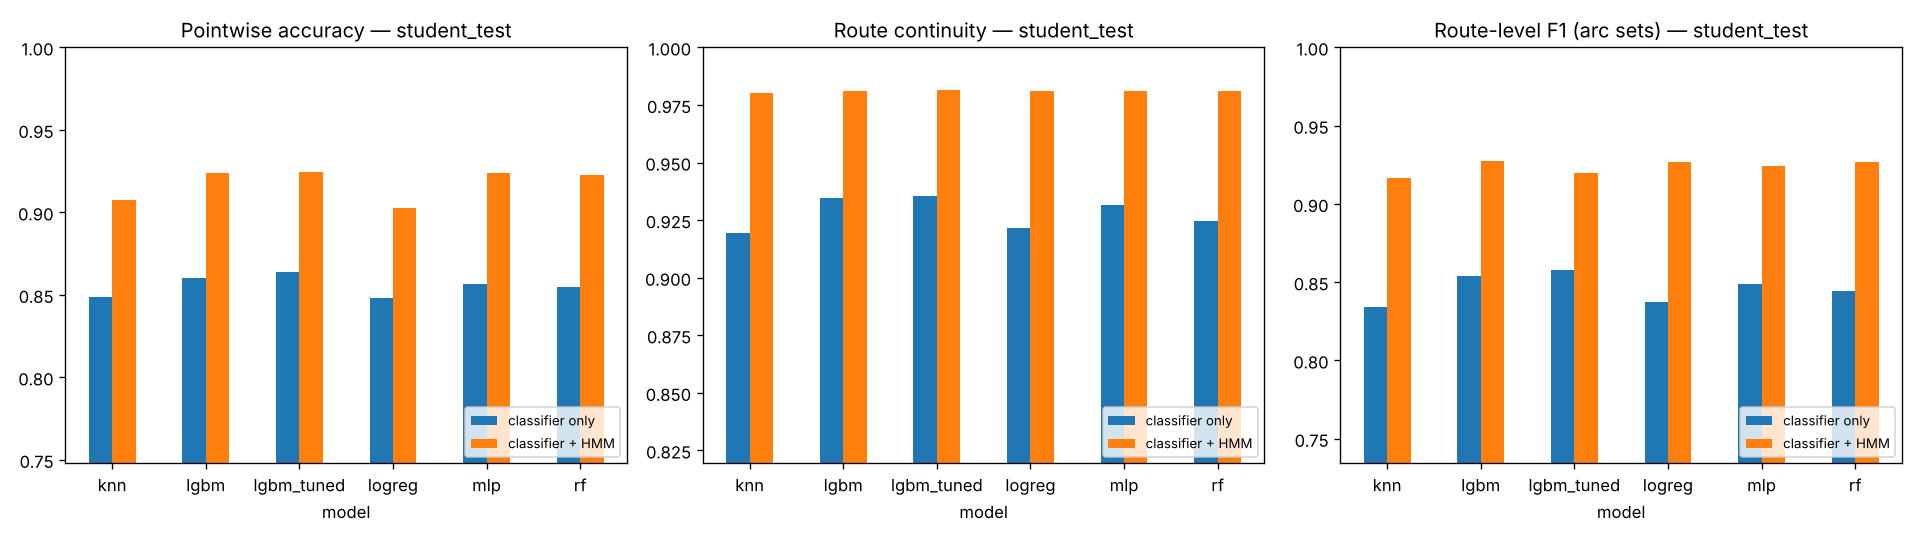

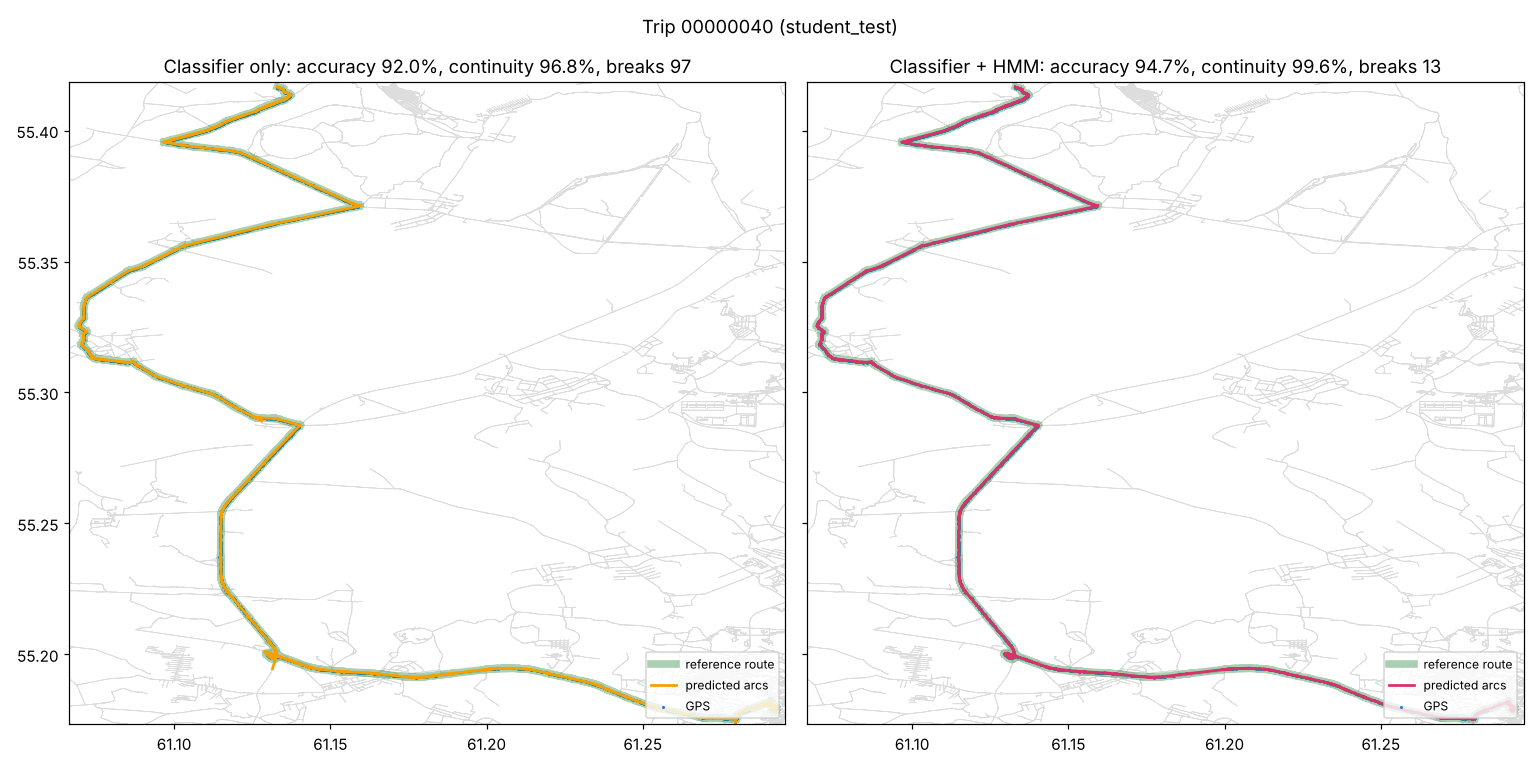

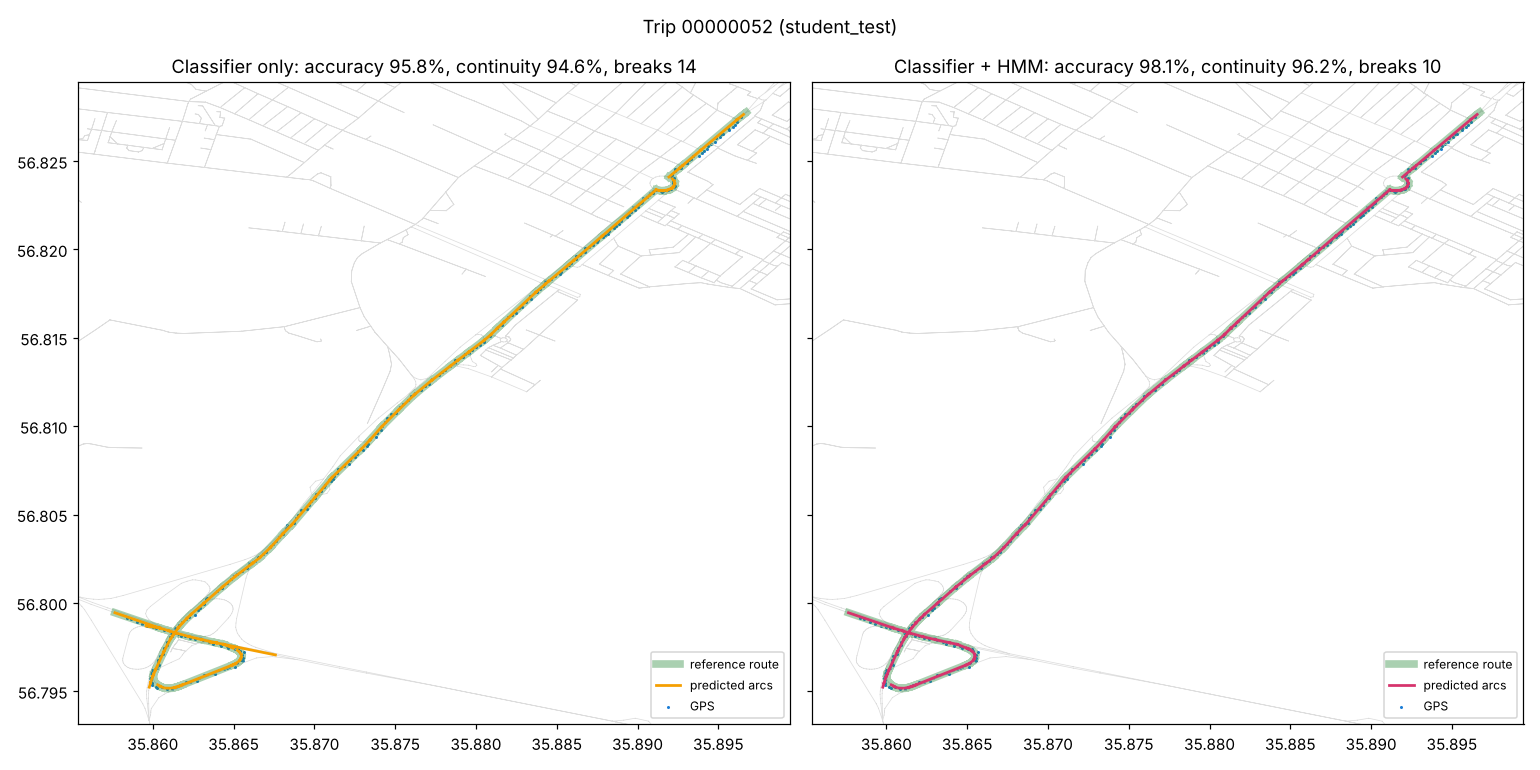

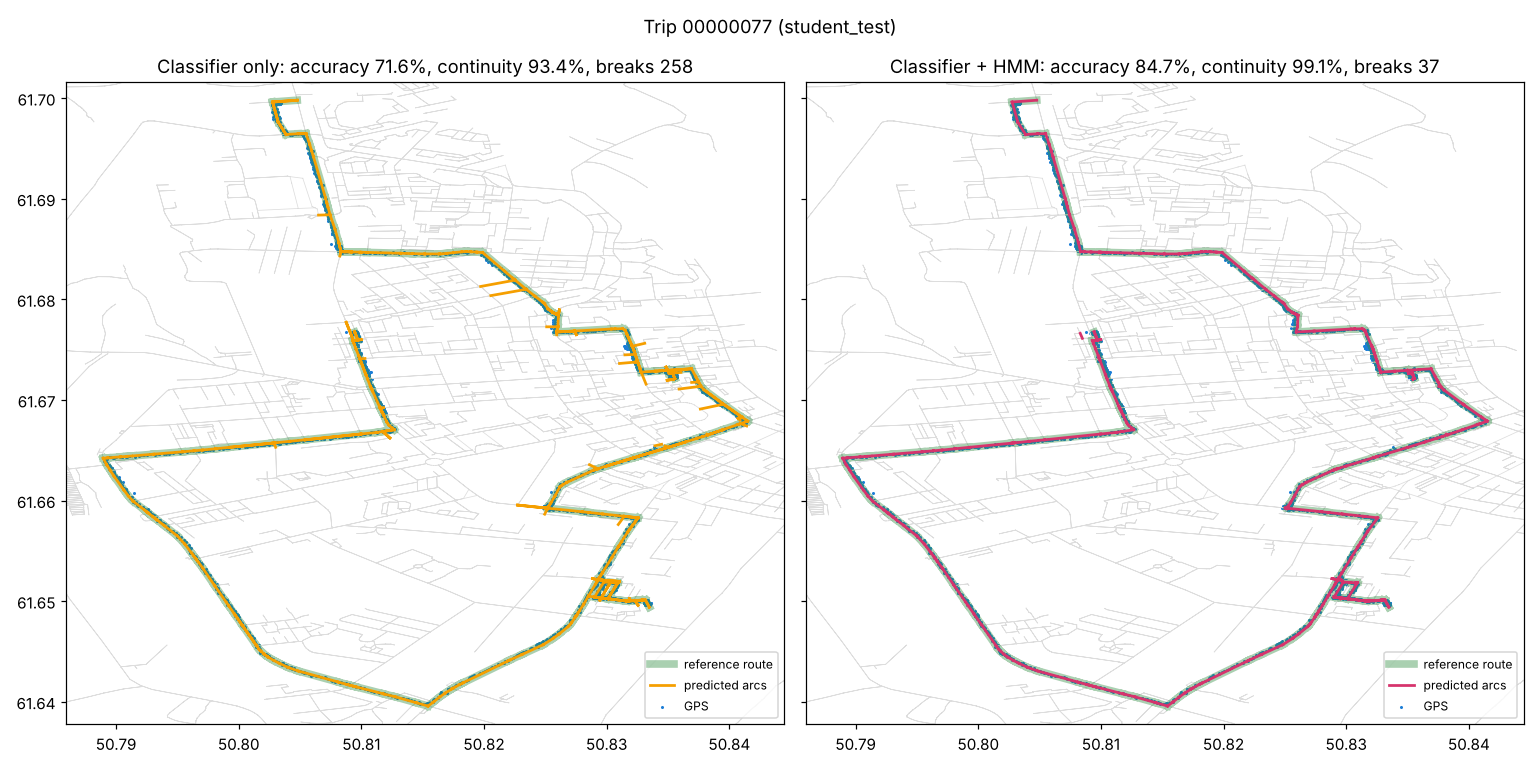

In [6]:
display(pd.read_csv('../results/hmm/comparison.csv').round(4))
display(Image('../results/hmm/classifier_vs_hmm.png'))
import glob
for p in sorted(glob.glob('../results/hmm/route_*.png')):
    display(Image(p))

## Step 6 — Where HMM did not help
**What we say:** In trip 00000007 the car is **parked** for its last ~175 points on a two-way road. At standstill the GPS heading is noise, so the classifier prefers the opposite-direction arc. Over many points that evidence outweighs one U-turn transition, and the decoder switches direction even though the road geometry is identical. Our planned fix is a speed-aware heading feature.

In [7]:
res[res.trip == '00000007'][['method', 'pointwise_accuracy', 'route_continuity', 'n_breaks', 'route_f1']].round(4)

,method,pointwise_accuracy,route_continuity,n_breaks,route_f1
2,classifier only,0.9025,0.9963,5,0.9680
3,classifier + HMM,0.8951,1.0000,0,0.9878
